<a href="https://colab.research.google.com/github/niteshbansal07/phys3130_nb/blob/main/Quiz3_UFOs_data_grouping_nitesh_bansal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Quiz 3: Investigating UFO's with data and grouping

_Phys3130: Dr. Elaina Hyde_

---

You are going to investigate UFO sightings around the US.  This quiz will give you some data investigation practice by using the solutions from your crossword puzzle and performing `groupby` operations to split data along multiple dimensions and investigate patterns between subsets of the data using basic aggregation.

All students have until end of Saturday Feb 8th to upload their crossword pdf AND this notebook (renamed, with your name at the end) into their private github repos for the class.

**Remember to CITE when copying code or using AI, in-line citations are fine**

### How to turn in this assignment
* Finish the crossword puzzle for Quiz3
* Take a photo or scan it in and save as pdf or image file
* Upload to your private GitHub repo as Quiz3_crossword_yourname
* Save a copy of the quiz in your drive and rename
* Use the crossword and our 'Titanic' solutions from Wednesday to complete the Quiz
* Upload the renamed, finished Quiz3 onto GitHub

### Quiz 3 Student Solutions
---

Student Name: [Nitesh Bansal] \\
Date of upload: [2/8/2025] \\

---

In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style('whitegrid')

%matplotlib inline
%config InlineBackend.figure_format ='retina'

#### 1. Load and print the header for the UFO data.

In [7]:
from google.colab import drive
drive.mount("/content/drive")

#check that the data is findable on your colab notebook
!ls /content/drive/MyDrive/ufo.csv


Mounted at /content/drive
/content/drive/MyDrive/ufo.csv


In [8]:
# A:

df = pd.read_csv('/content/drive/MyDrive/ufo.csv')
print(df.head())
df.columns

                   City Colors Reported Shape Reported State             Time
0                Ithaca             NaN       TRIANGLE    NY   6/1/1930 22:00
1           Willingboro             NaN          OTHER    NJ  6/30/1930 20:00
2               Holyoke             NaN           OVAL    CO  2/15/1931 14:00
3               Abilene             NaN           DISK    KS   6/1/1931 13:00
4  New York Worlds Fair             NaN          LIGHT    NY  4/18/1933 19:00


Index(['City', 'Colors Reported', 'Shape Reported', 'State', 'Time'], dtype='object')

#### 2. Use the answer to the crossword for 17 across to describe this data, why is it accurate?



In [9]:
# A:
#answer for 17 across is Positivism
#Using positivism, this data could be described as factual observations of the UFO using the city, colors, shape and time. This could be emperically verified , therefore accepted.

#### 3. Use the answer to the crossword for 22 across to come up with a science use case for this data, is it a good method you have used?

In [10]:
# A:
#Answer for 22 across is Brainstorming
# Imagine a ufo spotting is always followed by rain i.e. there are some environmental effects always following a UFO. I would just like to see if it is possible that a ufo in sky could change some climate and it seems like a good data for it.

#### 4. How many null values exist per column?

In [11]:
# A:
df.isnull().sum()

,0
City,51
Colors Reported,63509
Shape Reported,8402
State,0
Time,0


#### 5. Which city has the most observations?

In [12]:
# A:
df['City'].value_counts()
#Seattle does

,count
City,
Seattle,646
New York City,612
Phoenix,533
Las Vegas,442
Portland,438
...,...
Middlesex Township,1
Washington Courthouse,1
Clare,1


#### 6. What is the observation count per shape?

In [13]:
# A:
df['Shape Reported'].value_counts()

,count
Shape Reported,
LIGHT,16332
TRIANGLE,7816
CIRCLE,7725
FIREBALL,6249
OTHER,5506
SPHERE,5231
DISK,5226
OVAL,3721
FORMATION,2405


#### 7. Create a subset of the data that is the top 5 cities and the top 5 shapes.

In [14]:
# A:
#I used the doc to find how to concatenate two conditions in pandas df
subset_df = df[df['City'].isin(df['City'].value_counts().head(5).index) & df['Shape Reported'].isin(df['Shape Reported'].value_counts().head(5).index)]


print(subset_df)


                City Colors Reported Shape Reported State             Time
96     New York City             NaN         CIRCLE    NY    8/1/1948 2:00
208    New York City             NaN          OTHER    NY  7/15/1952 19:00
313    New York City             NaN          LIGHT    NY  2/15/1955 19:00
367    New York City             NaN          LIGHT    NY  6/15/1956 21:00
568    New York City             NaN          OTHER    NY  10/1/1959 16:00
...              ...             ...            ...   ...              ...
80189  New York City          ORANGE         CIRCLE    NY  8/23/2014 21:10
80269       Portland             NaN          LIGHT    ME  8/25/2014 21:30
80315        Phoenix            BLUE         CIRCLE    AZ  8/27/2014 20:30
80361        Seattle          YELLOW         CIRCLE    WA  8/28/2014 22:00
80383  New York City             NaN         CIRCLE    NY  8/29/2014 21:40

[1322 rows x 5 columns]


#### 8. With the subset, find the percent of each shape seen by city.

In [27]:
# A:\
#I needed a lot of help in this and thus I used doc and chatgpt to arrange the code and get the first line of code
city_shape_counts = subset_df.groupby(['City', 'Shape Reported']).size().reset_index(name='count')

city_shape_counts['total_by_city'] = city_shape_counts.groupby('City')['count'].transform('sum')

city_shape_counts['percent'] = (city_shape_counts['count'] / city_shape_counts['total_by_city']) * 100

print("\nPercent of each shape seen by city:")
print(city_shape_counts[['City', 'Shape Reported', 'count', 'percent']])

pivot_percent = city_shape_counts.pivot(index='City', columns='Shape Reported', values='percent').fillna(0)
print("\nPivot table of percentage distribution:")
print(pivot_percent)



Percent of each shape seen by city:
             City Shape Reported  count    percent
0       Las Vegas         CIRCLE     42  19.444444
1       Las Vegas       FIREBALL     22  10.185185
2       Las Vegas          LIGHT     85  39.351852
3       Las Vegas          OTHER     36  16.666667
4       Las Vegas       TRIANGLE     31  14.351852
5   New York City         CIRCLE     56  20.143885
6   New York City       FIREBALL     35  12.589928
7   New York City          LIGHT    105  37.769784
8   New York City          OTHER     42  15.107914
9   New York City       TRIANGLE     40  14.388489
10        Phoenix         CIRCLE     34  12.781955
11        Phoenix       FIREBALL     35  13.157895
12        Phoenix          LIGHT    106  39.849624
13        Phoenix          OTHER     46  17.293233
14        Phoenix       TRIANGLE     45  16.917293
15       Portland         CIRCLE     46  19.913420
16       Portland       FIREBALL     29  12.554113
17       Portland          LIGHT    100  43.2

**9. Make a grouped bar chart with your subset data showing counts of shapes seen by city.**

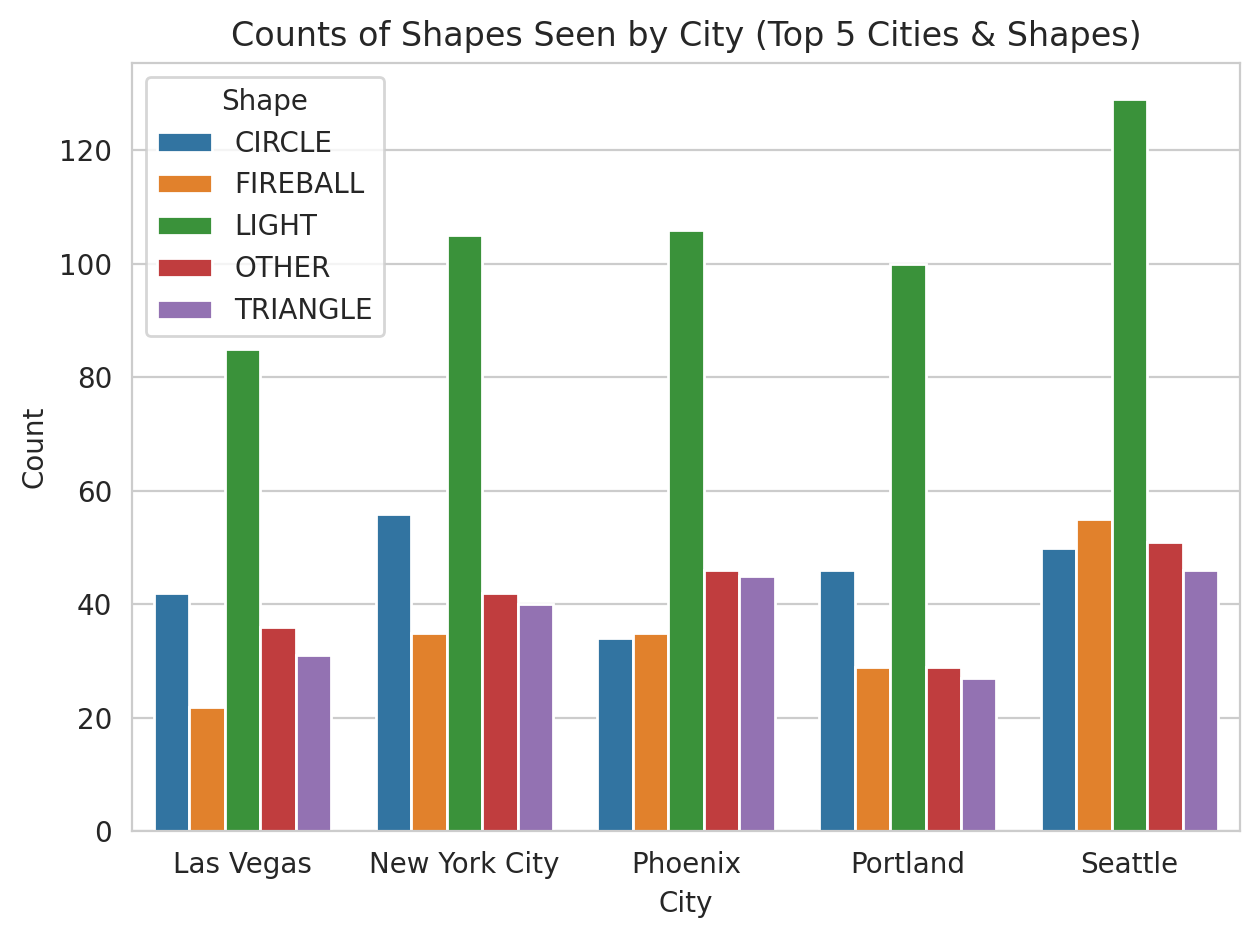

In [26]:
sns.barplot(data=city_shape_counts, x='City', y='count', hue='Shape Reported')

plt.title('Counts of Shapes Seen by City (Top 5 Cities & Shapes)')
plt.xlabel('City')
plt.ylabel('Count')
plt.legend(title='Shape')

plt.tight_layout()
plt.show()